In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("dataset_final.csv")
df

,Unnamed: 0,text,topic,is_noise_or_spam_text,toxicity,polarized,profanity_obscenity,threat_incitement_to_violence,insults,identity_attack,...,ethnicity,religion,disability,lgbt,gender,age,domisili,pendidikan terakhir,status pekerjaan,president vote leaning
0,0,Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,...,Minang,Islam,yes,no,F,27,Padang,Sarjana (S1),Bekerja,1
1,1,Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,...,Tionghoa,Katolik,yes,no,F,21,Jakarta,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,3
2,2,Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,...,Minang,Islam,yes,no,F,27,Padang,Sarjana (S1),Bekerja,1
3,3,Wajah Jurnalis Dibalut Perban Saat Melaporkan ...,UNKNOWN,0,0,0,0,0,0,0,...,Tionghoa,Katolik,yes,no,F,21,Jakarta,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,3
4,4,Elektabilitas Paslon 02 sebentar lagi terjun b...,Disabilitas,0,0,1,0,0,0,0,...,Minang,Islam,yes,no,F,27,Padang,Sarjana (S1),Bekerja,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51998,51998,@pippsstudy abis packing nnt ingfokan cowo kri...,Kristen,0,0,0,0,0,0,0,...,Batak,Kristen,no,no,F,39,Depok,Magister (S2),Bekerja,2
51999,51999,Akun WhatsApp Pj Bupati Tegal Agustyarsah,UNKNOWN,0,0,0,0,0,0,0,...,Batak,Kristen,no,no,F,39,Depok,Magister (S2),Bekerja,2
52000,52000,Buldoser Israel Menabrak Pengungsi Pasien Ruma...,"Jewish, Rohingya",0,0,1,0,0,0,0,...,Batak,Kristen,no,no,F,39,Depok,Magister (S2),Bekerja,2
52001,52001,Perayaan Chinese New Year tahun ini ya akan ma...,Tionghoa,0,0,0,0,0,0,0,...,Batak,Kristen,no,no,F,39,Depok,Magister (S2),Bekerja,2


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52003 entries, 0 to 52002
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Unnamed: 0                     52003 non-null  int64
 1   text                           52003 non-null  str  
 2   topic                          52003 non-null  str  
 3   is_noise_or_spam_text          52003 non-null  int64
 4   toxicity                       52003 non-null  int64
 5   polarized                      52003 non-null  int64
 6   profanity_obscenity            52003 non-null  int64
 7   threat_incitement_to_violence  52003 non-null  int64
 8   insults                        52003 non-null  int64
 9   identity_attack                52003 non-null  int64
 10  sexually_explicit              52003 non-null  int64
 11  cleaned_text                   52003 non-null  str  
 12  processed_text                 52003 non-null  str  
 13  ethnicity                  

In [4]:
df_metadata = pd.read_csv("annotator_demographic.csv")
df_metadata

,annotator_id,ethnicity,religion,disability,lgbt,gender,age,domisili,pendidikan terakhir,status pekerjaan,president vote leaning
0,1,Tionghoa,Kristen,no,no,F,50,Jakarta,Diploma,Bekerja,2
1,2,Madura,Islam,no,no,F,22,Madura,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,3
2,3,Batak,Kepercayaan Lokal,no,no,F,29,Medan,Sarjana (S1),Bekerja,3
3,4,Bali,Hindu,no,no,M,23,Bandung,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,-
4,5,Jawa,Syiah,no,no,M,46,Bandung,Diploma,Bekerja,Golput
5,6,Minang,Ahmadiyah,no,no,F,22,Jakarta,Sarjana (S1),Bekerja,3
6,7,Minang,Islam,yes,no,F,27,Padang,Sarjana (S1),Bekerja,1
7,8,Arab,Islam,no,no,M,23,Jakarta,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,1
8,9,Jawa,Islam,no,no,F,21,Magelang,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,2
9,10,Tionghoa,Buddha,no,no,F,20,Tangerang,Sekolah Menengah Atas (SMA),Pelajar/Mahasiswa,3


In [5]:
METADATA_COLS = df_metadata.columns.to_list()
METADATA_COLS.remove("annotator_id")
METADATA_COLS

['ethnicity',
 'religion',
 'disability',
 'lgbt',
 'gender',
 'age',
 'domisili',
 'pendidikan terakhir',
 'status pekerjaan',
 'president vote leaning']

In [10]:
LABEL_COLS = [
    "toxicity",
    "insults",
    "identity_attack",
    "polarized",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit"
]

# Distribusi Label

In [7]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

## Distribusi Metadata

In [8]:
metadata_distribution = []

for col in METADATA_COLS:
    counts = df[col].fillna("Missing").value_counts(
        dropna=False
    )

    proportions = df[col].fillna("Missing").value_counts(
        normalize=True, dropna=False
    )

    for group in counts.index:
        metadata_distribution.append({
            "metadata": col,
            "group": group,
            "count": int(counts[group]),
            "proportion": proportions[group],
            "percentage": proportions[group] * 100
        })

metadata_dist_df = pd.DataFrame(metadata_distribution)

print("\n=== DISTRIBUSI METADATA ===")
print(metadata_dist_df.to_string(index=False))

metadata_dist_df.to_csv(
    "metadata_distribution.csv", index=False
)


=== DISTRIBUSI METADATA ===
              metadata                       group  count  proportion  percentage
             ethnicity                    Tionghoa   9381    0.180393   18.039344
             ethnicity                       Sunda   8520    0.163837   16.383670
             ethnicity                       Batak   5101    0.098090    9.809049
             ethnicity                        Bali   5065    0.097398    9.739823
             ethnicity                        Jawa   4351    0.083668    8.366825
             ethnicity                      Minang   3560    0.068458    6.845759
             ethnicity                       Bugis   3262    0.062727    6.272715
             ethnicity                       Dayak   2302    0.044267    4.426668
             ethnicity                      Melayu   2273    0.043709    4.370902
             ethnicity                        Aceh   1854    0.035652    3.565179
             ethnicity                        Arab   1328    0.025537

## Distribusi Label Berdasarkan Metadata

In [11]:
distribution_results = []

for meta in METADATA_COLS:
    for label in LABEL_COLS:

        temp = df[[meta, label]].copy()
        temp[meta] = temp[meta].fillna("Missing")

        # Label harus bernilai 0 atau 1
        temp[label] = pd.to_numeric(
            temp[label], errors="coerce"
        )
        temp = temp[temp[label].isin([0, 1])]

        if temp.empty:
            continue

        grouped = temp.groupby(meta, observed=True)[label]

        stats = grouped.agg(
            total="count",
            positive="sum"
        )

        stats["negative"] = stats["total"] - stats["positive"]
        stats["positive_pct"] = (
            stats["positive"] / stats["total"] * 100
        )
        stats["negative_pct"] = (
            stats["negative"] / stats["total"] * 100
        )

        for group, row in stats.iterrows():
            distribution_results.append({
                "metadata": meta,
                "label": label,
                "group": group,
                "total": int(row["total"]),
                "positive": int(row["positive"]),
                "negative": int(row["negative"]),
                "positive_pct": row["positive_pct"],
                "negative_pct": row["negative_pct"]
            })

distribution_df = pd.DataFrame(distribution_results)

print("\n=== DISTRIBUSI LABEL PER KELOMPOK METADATA ===")
print(distribution_df.to_string(index=False))


=== DISTRIBUSI LABEL PER KELOMPOK METADATA ===
              metadata                         label                       group  total  positive  negative  positive_pct  negative_pct
             ethnicity                      toxicity                        Aceh   1854       406      1448     21.898598     78.101402
             ethnicity                      toxicity                        Arab   1328        85      1243      6.400602     93.599398
             ethnicity                      toxicity                        Bali   5065      1388      3677     27.403751     72.596249
             ethnicity                      toxicity                    Balinese    939       333       606     35.463259     64.536741
             ethnicity                      toxicity                       Batak   5101       612      4489     11.997648     88.002352
             ethnicity                      toxicity                       Bugis   3262       627      2635     19.221337     80.778663


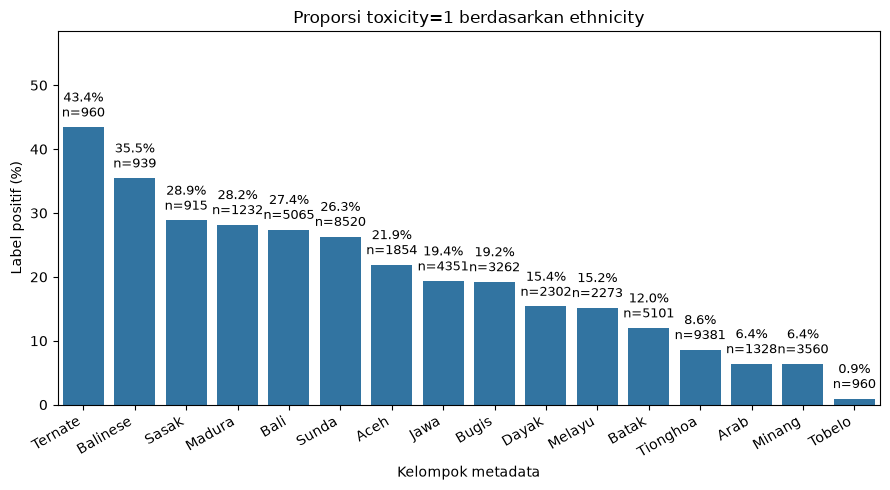

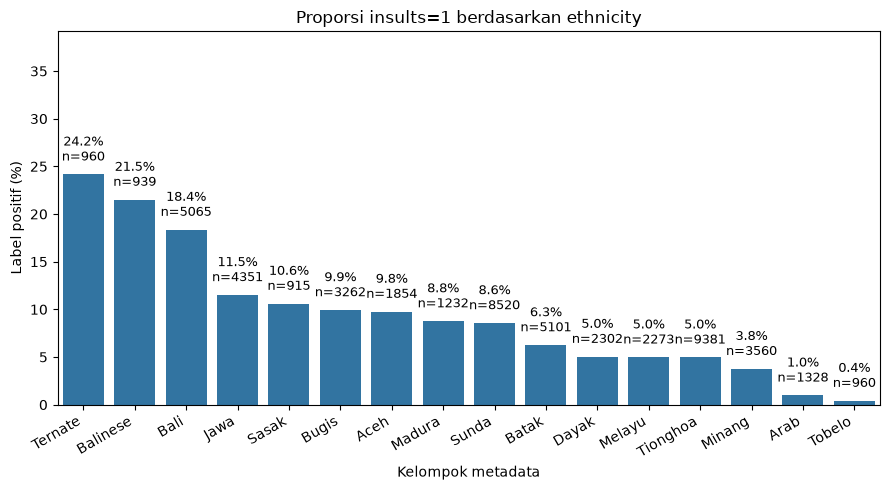

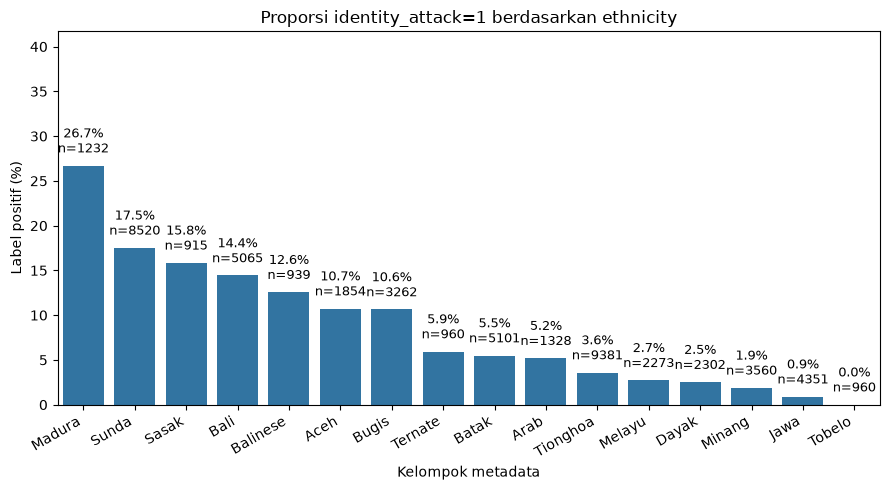

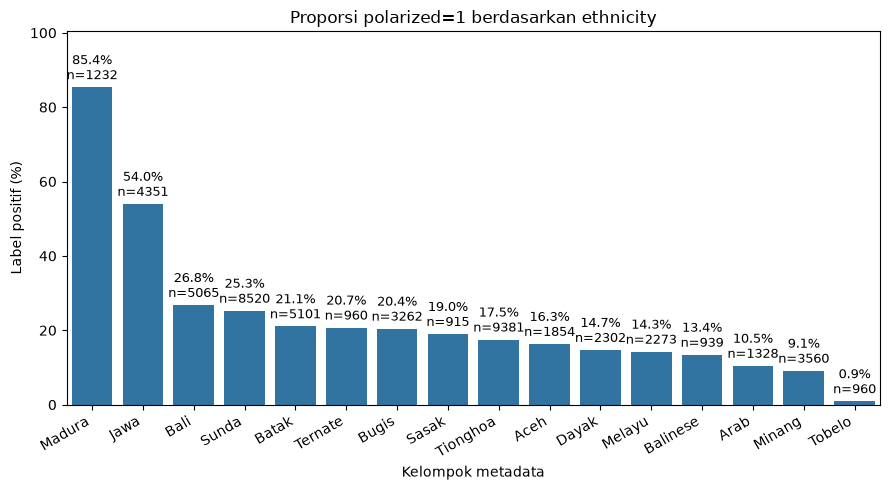

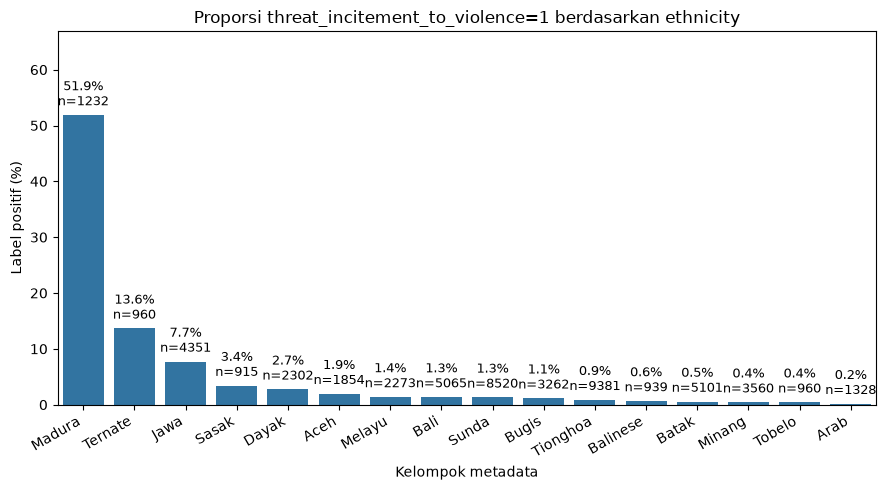

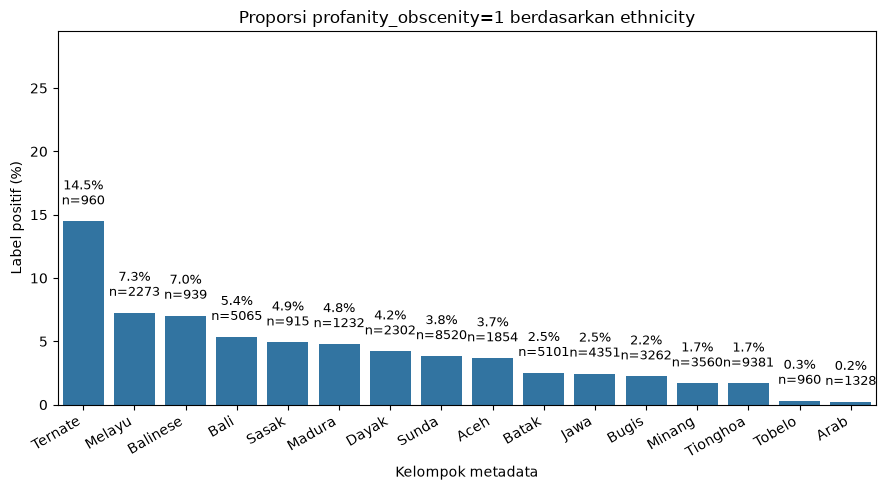

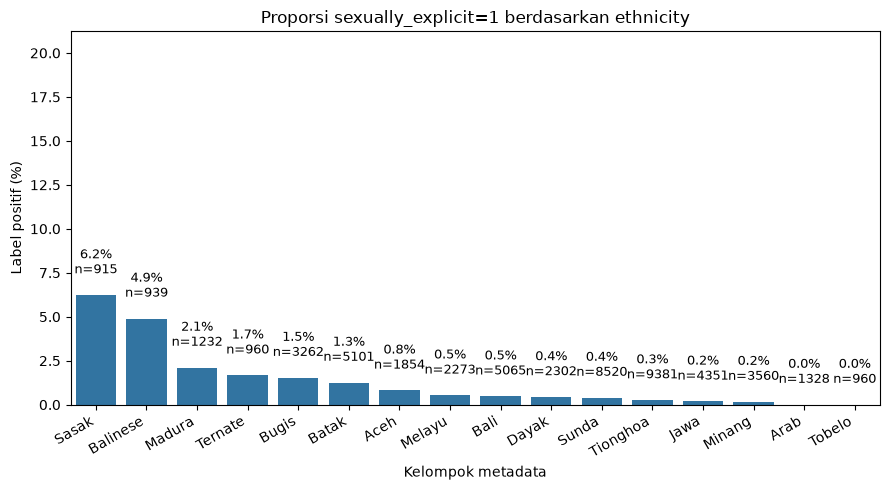

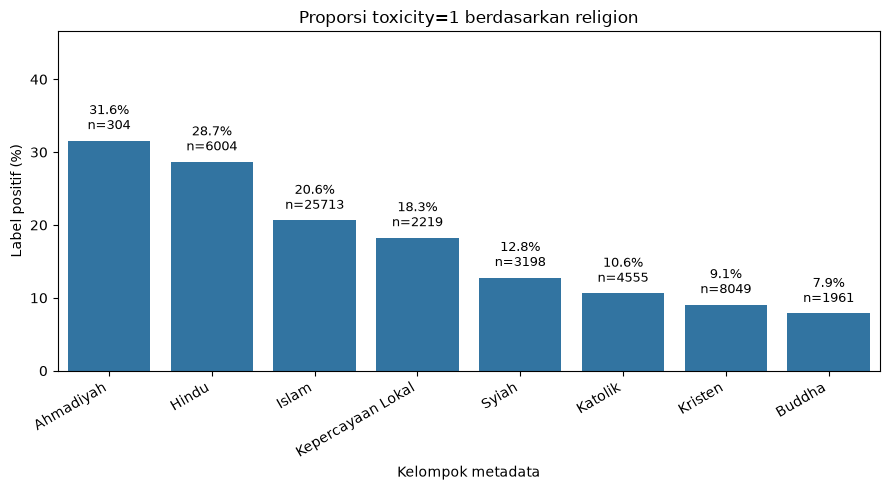

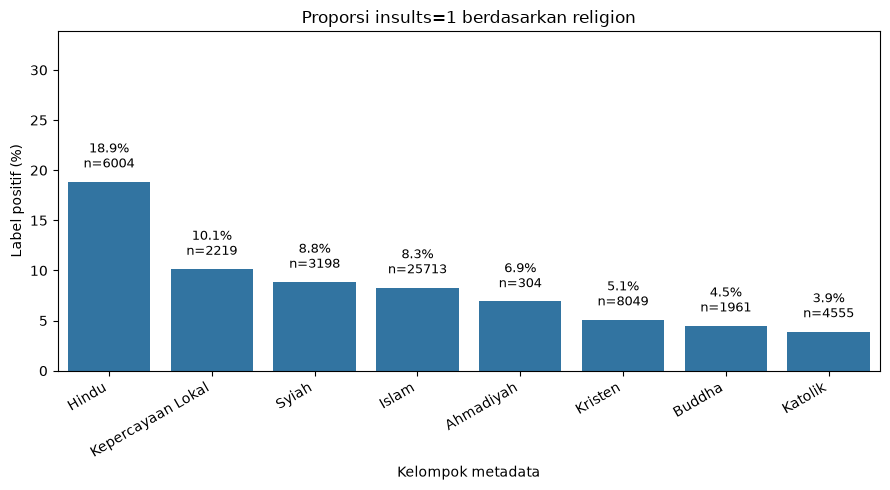

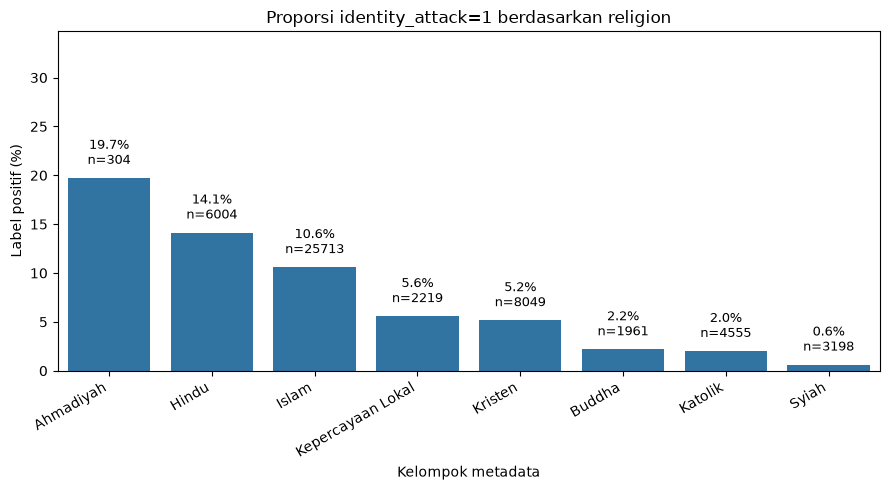

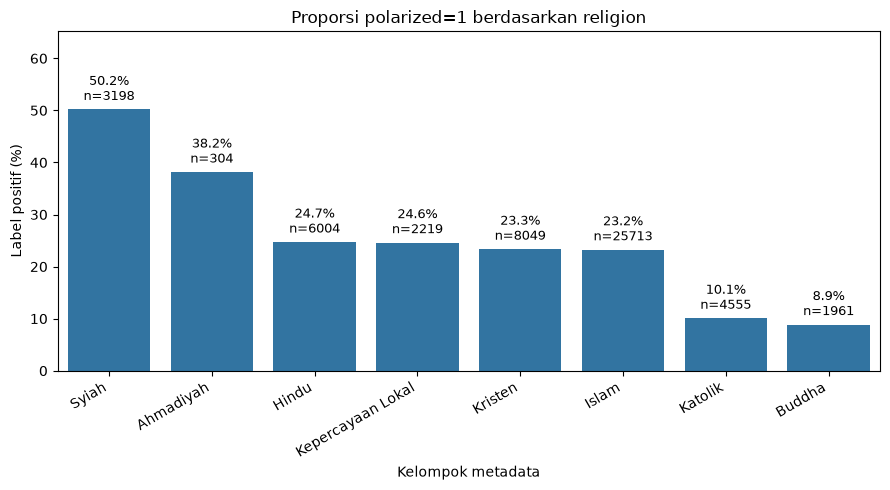

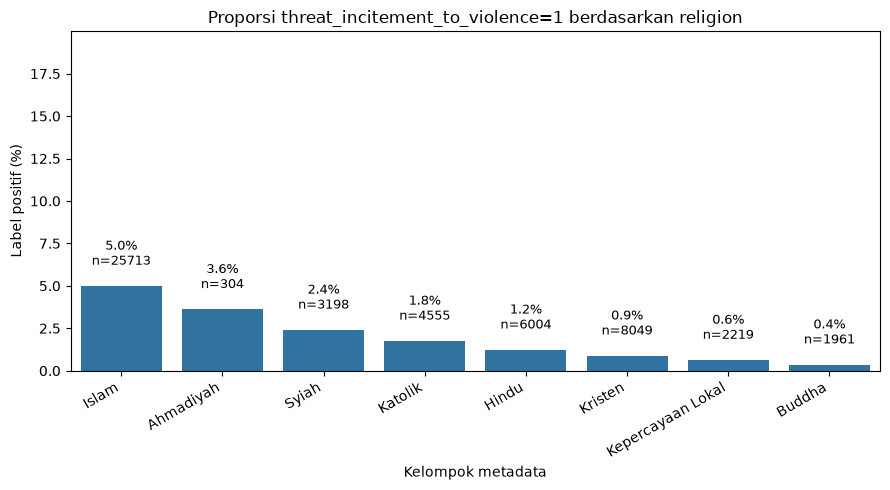

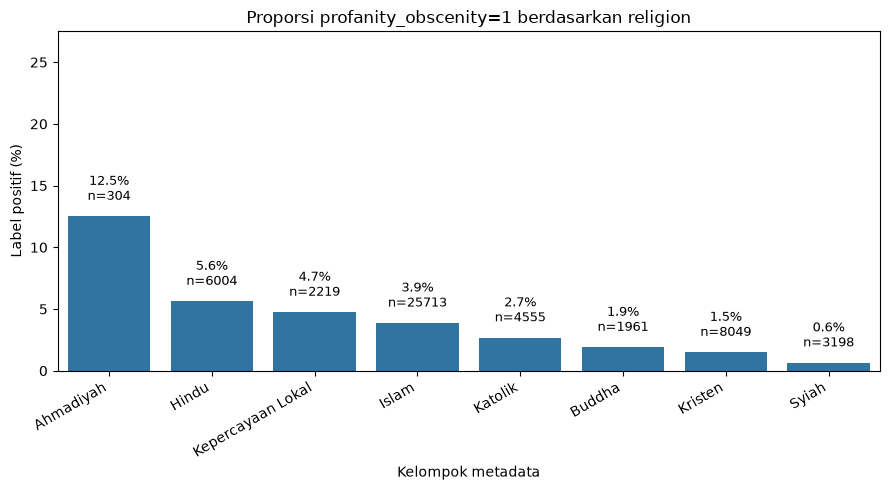

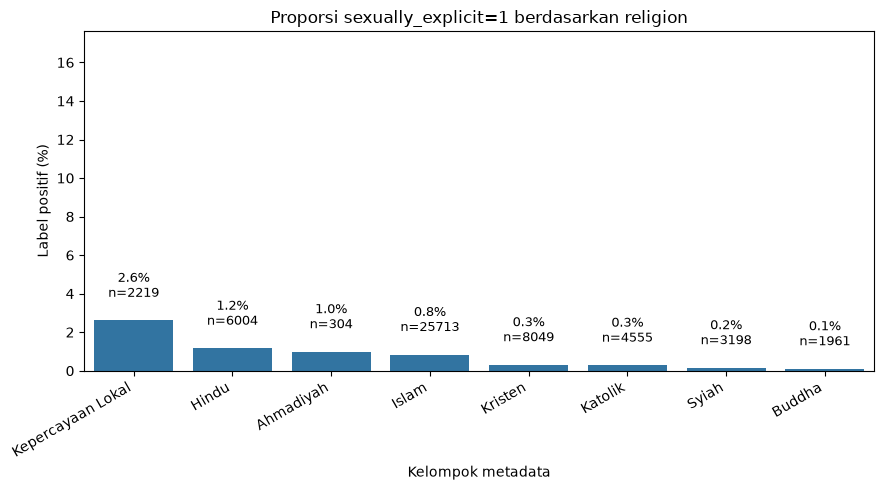

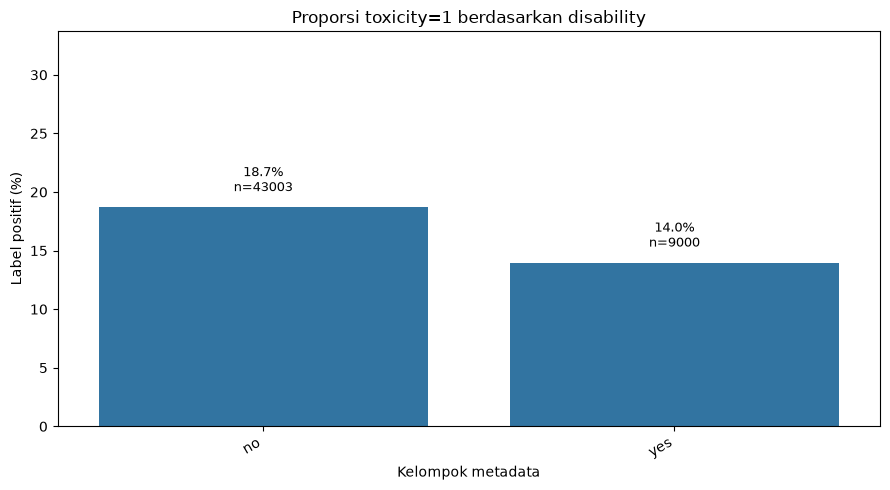

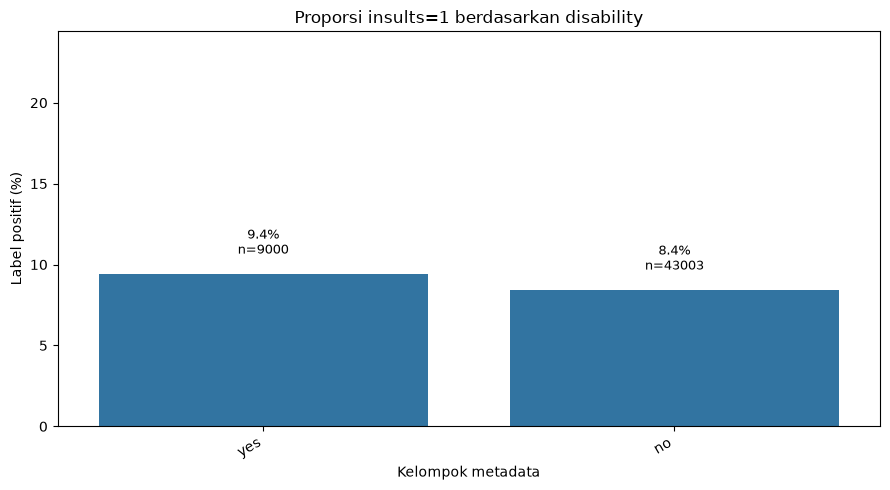

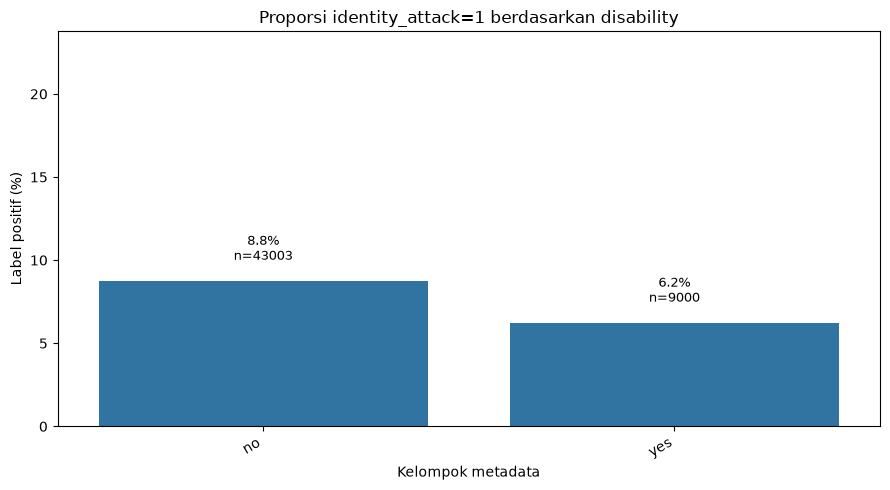

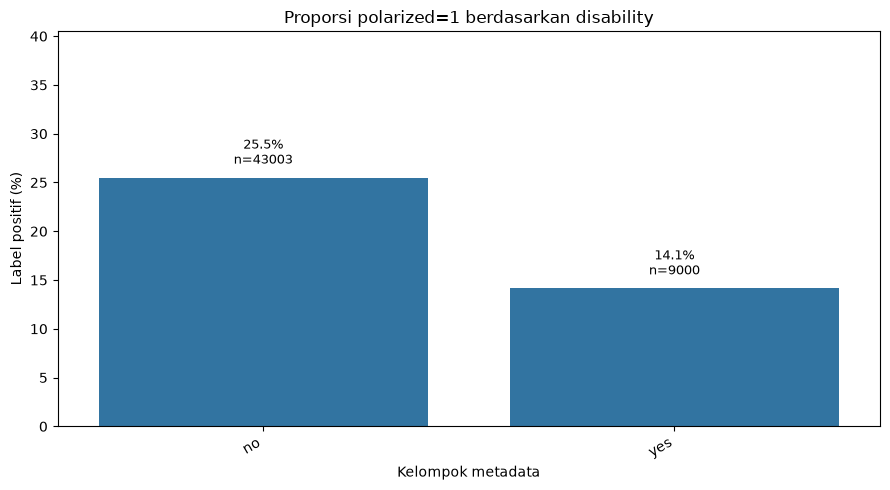

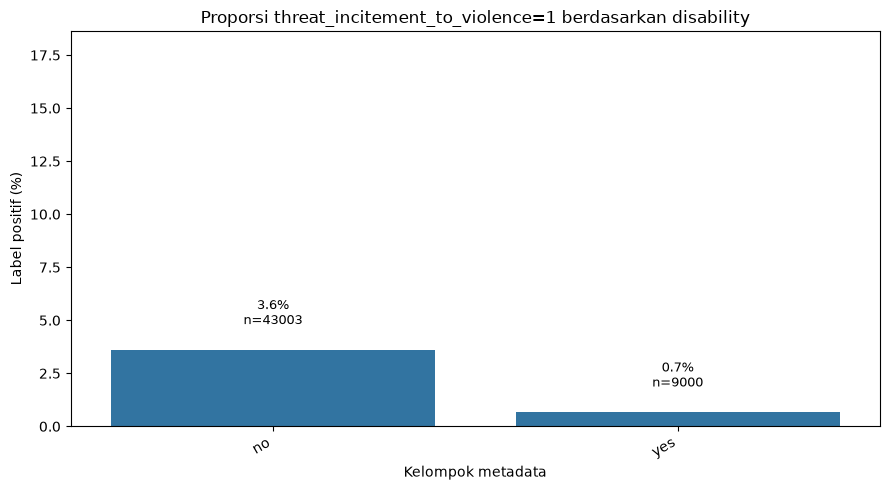

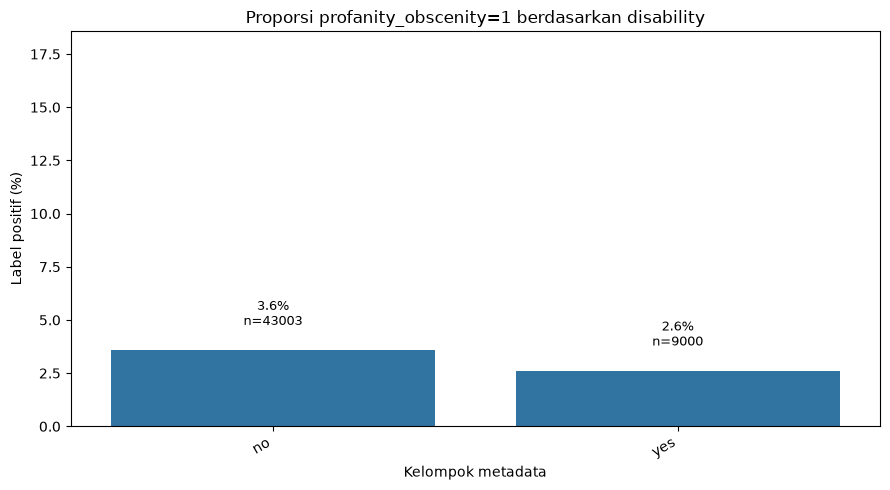

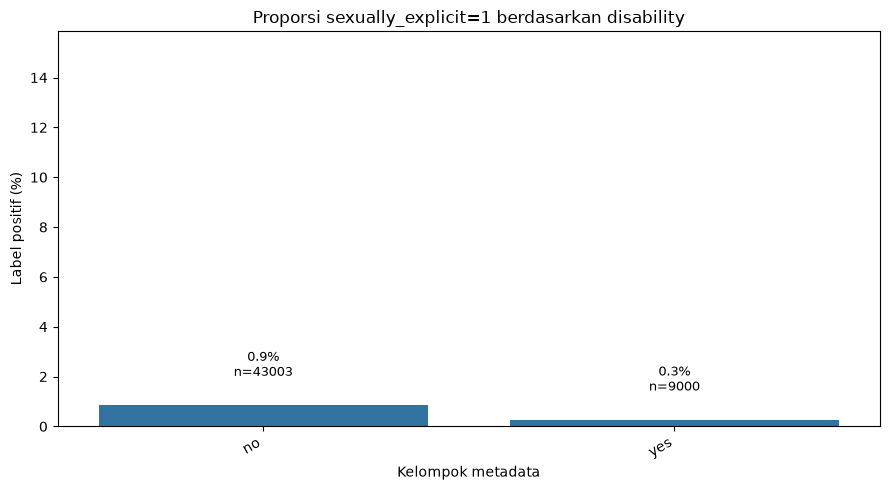

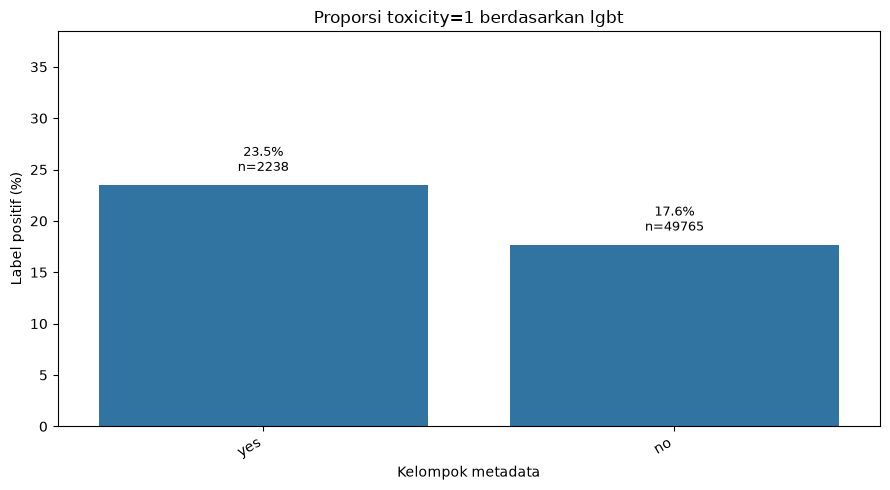

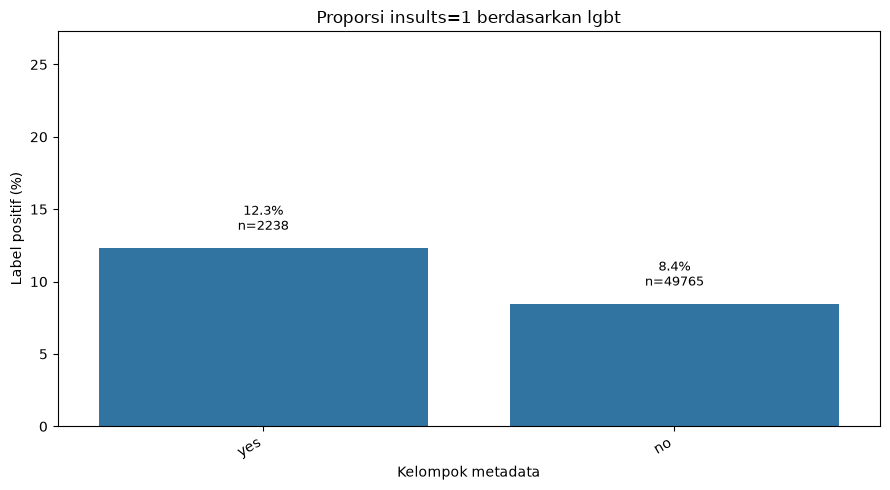

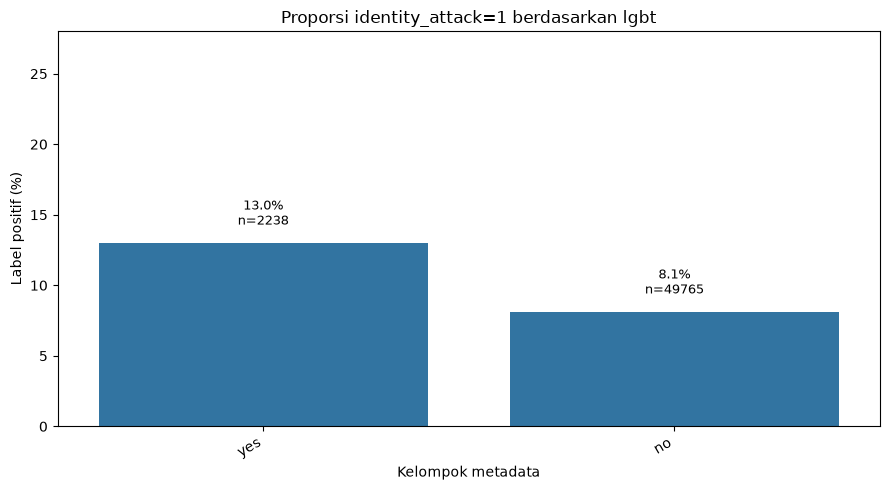

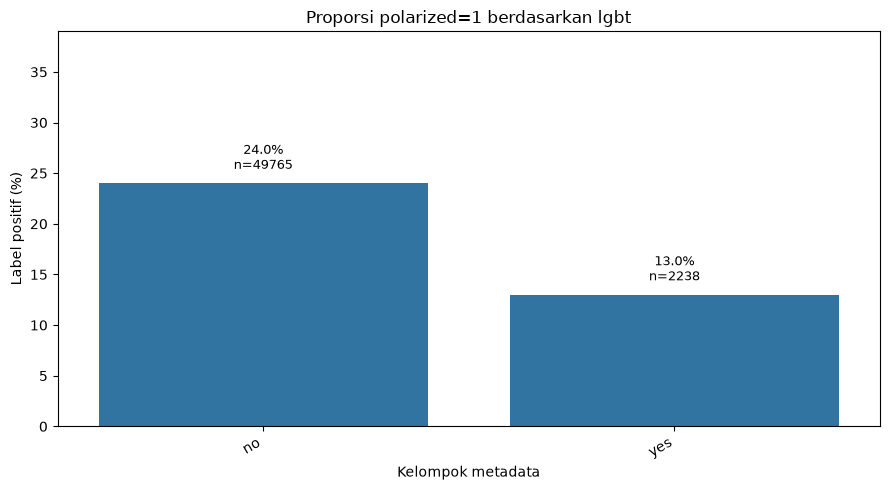

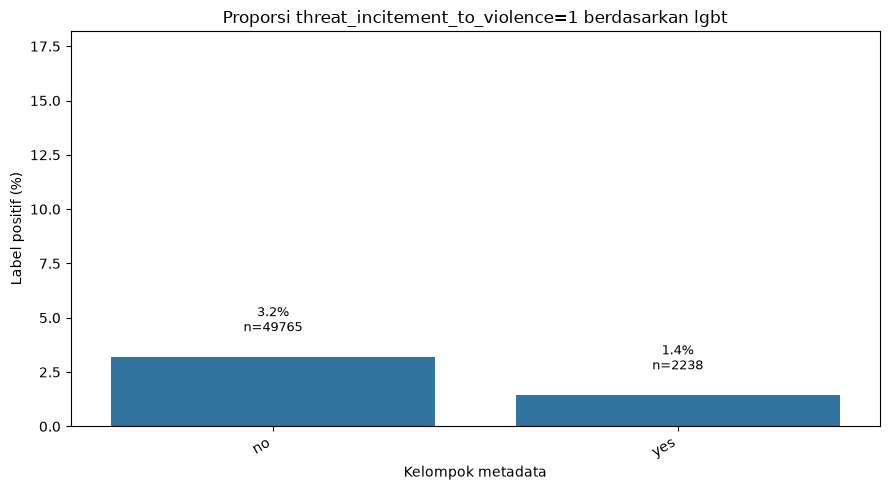

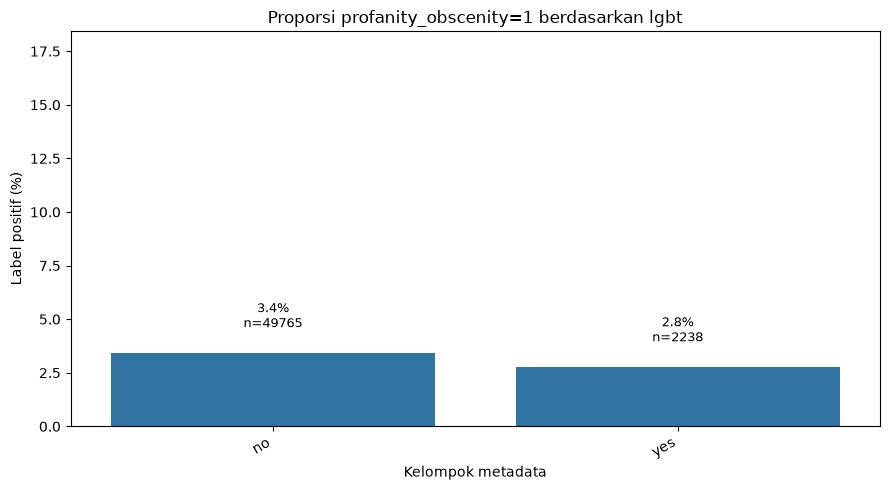

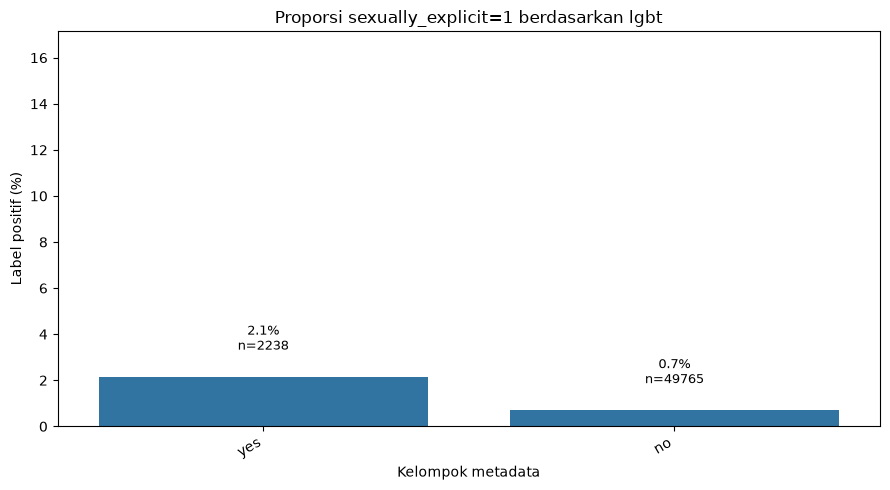

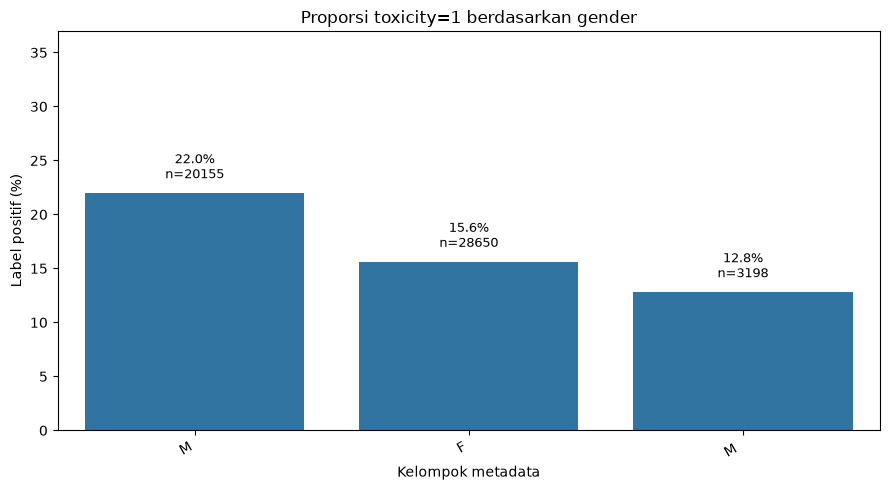

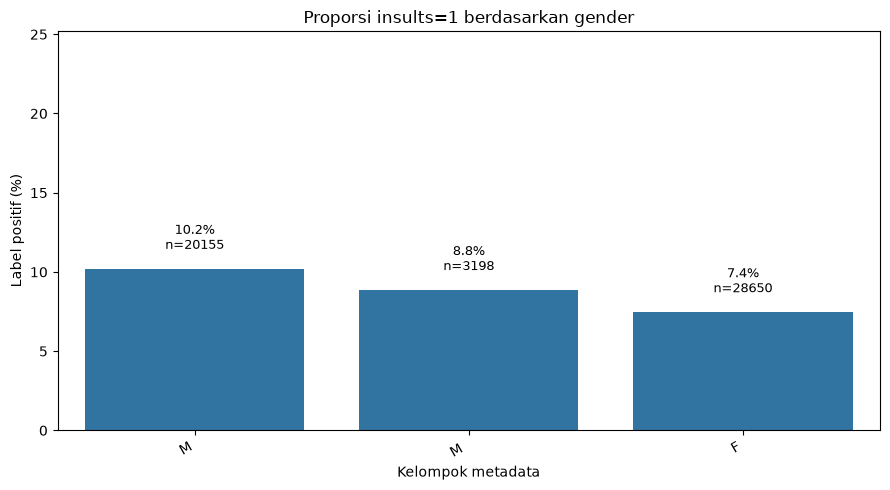

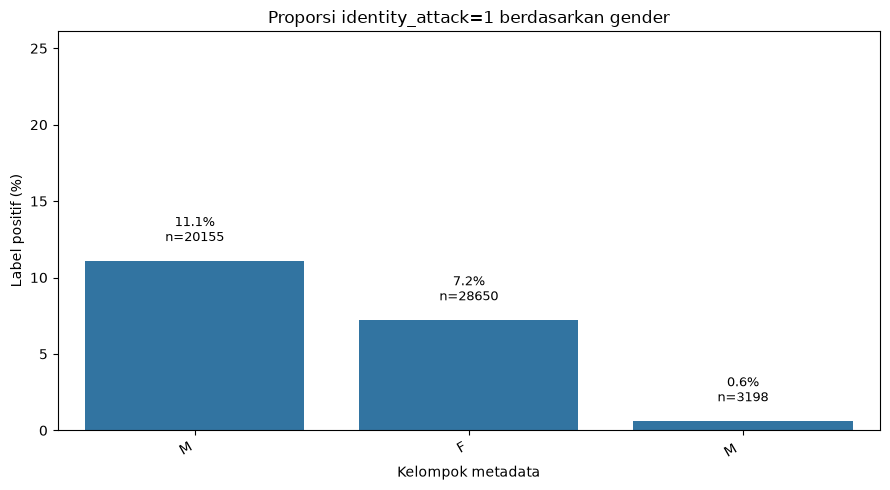

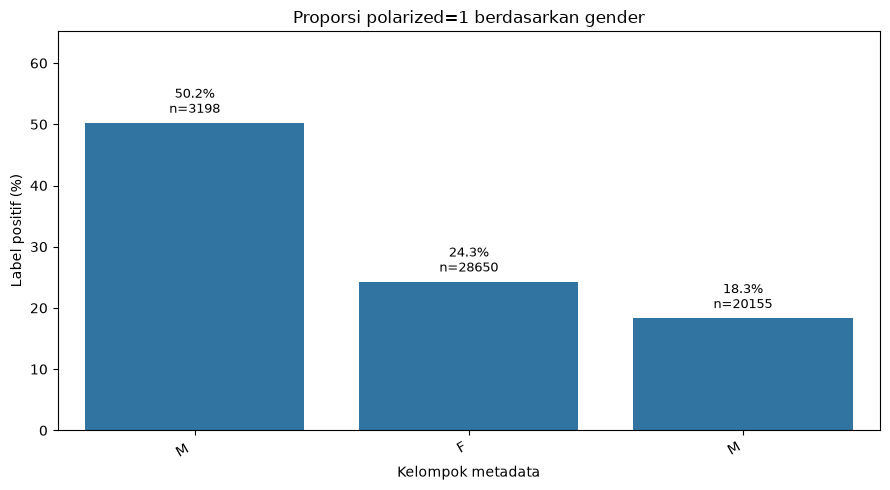

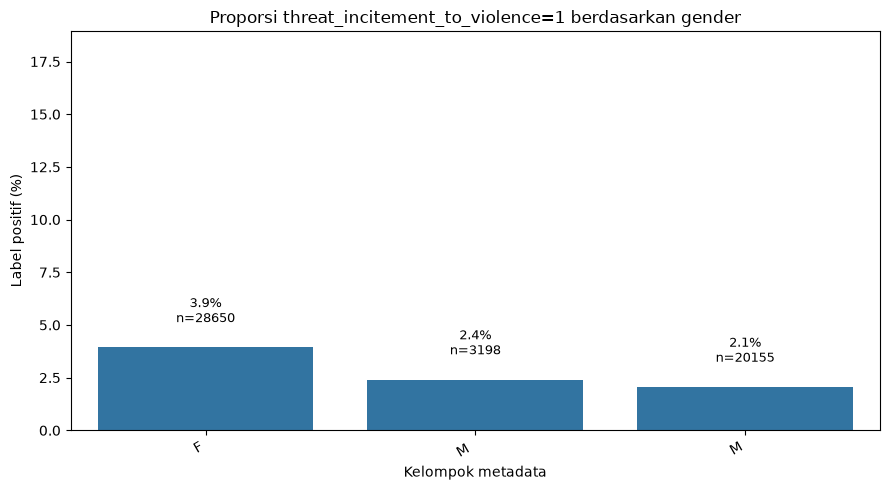

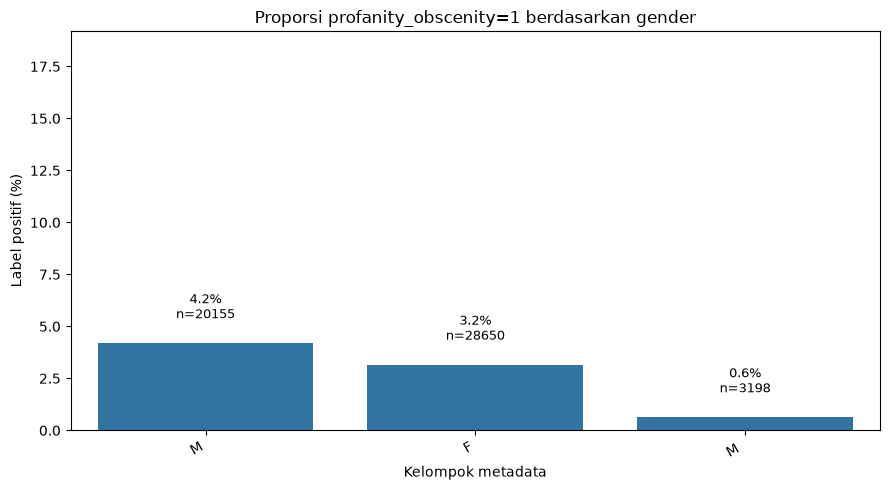

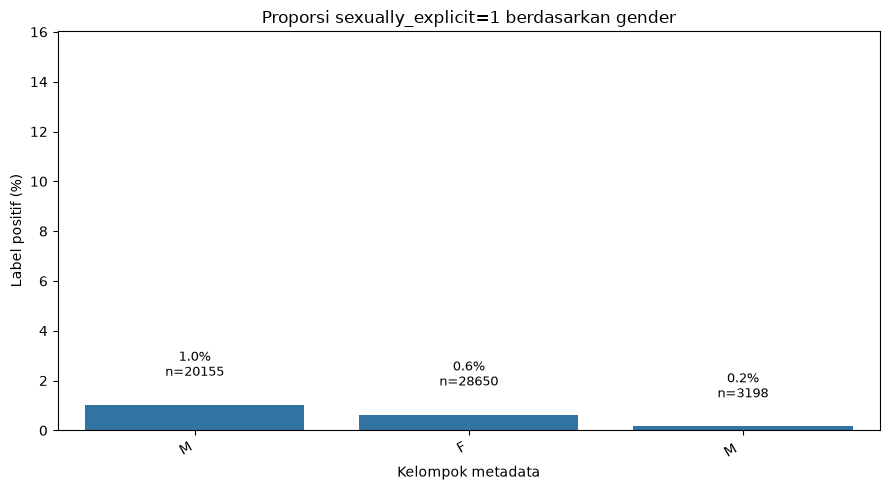

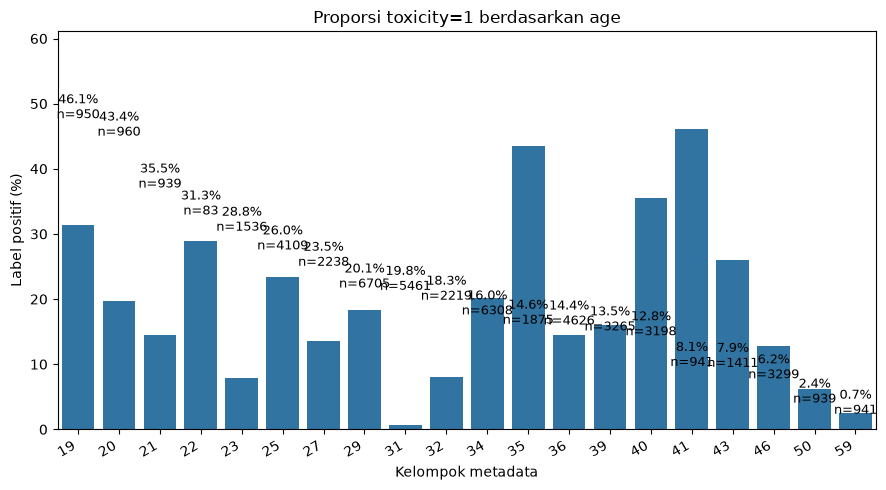

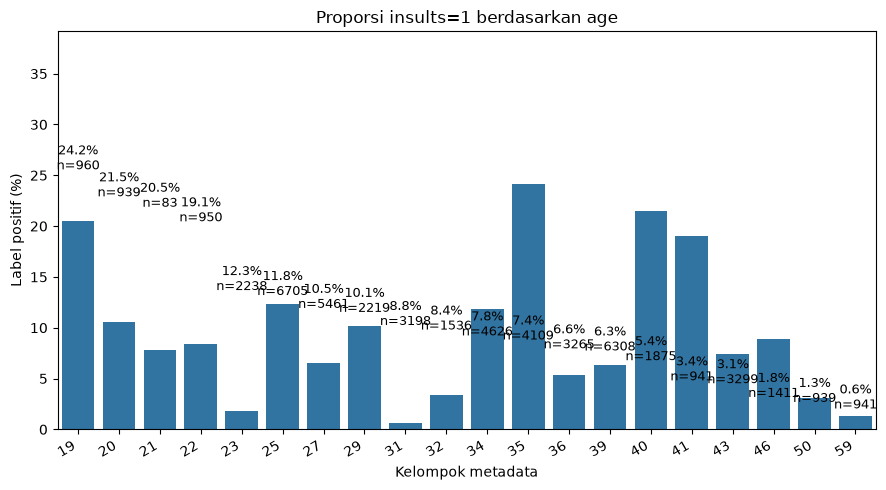

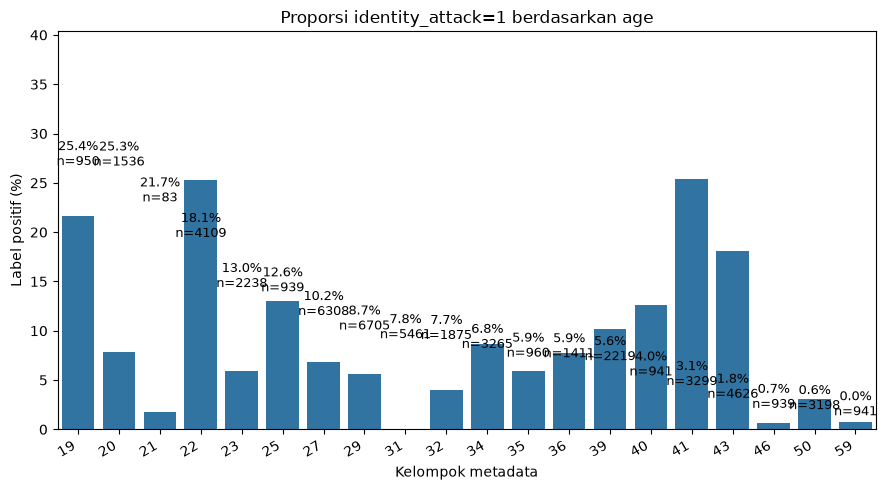

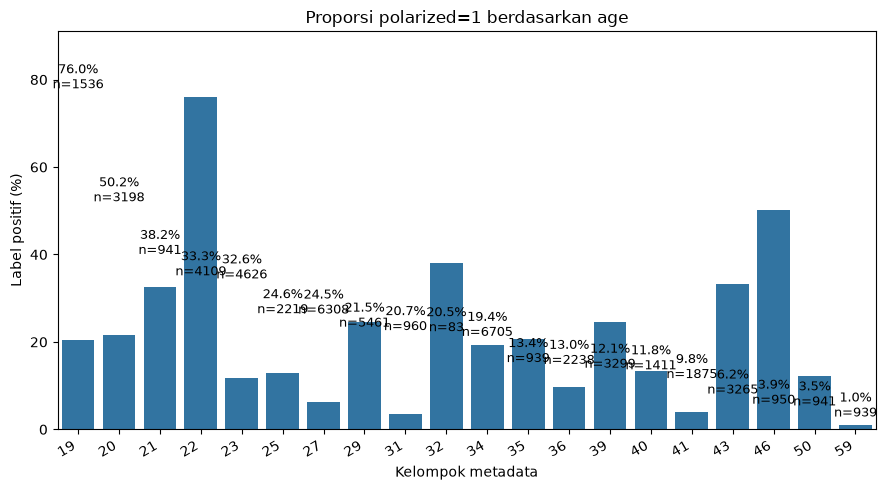

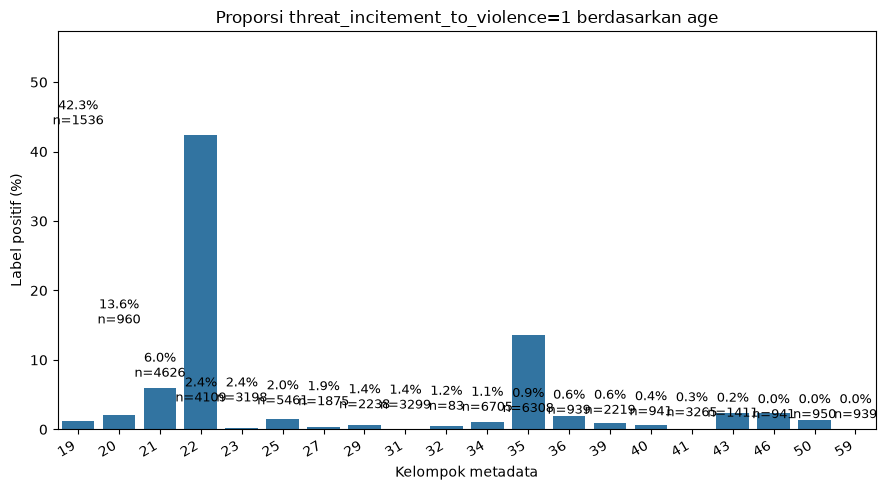

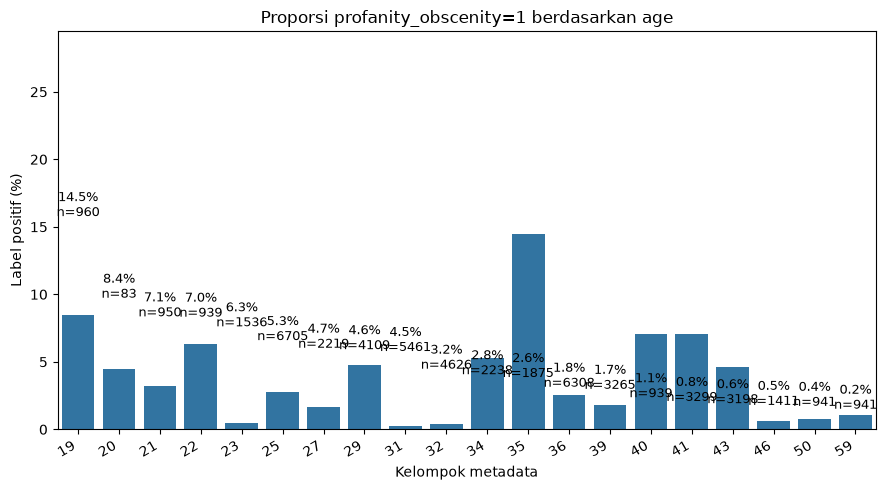

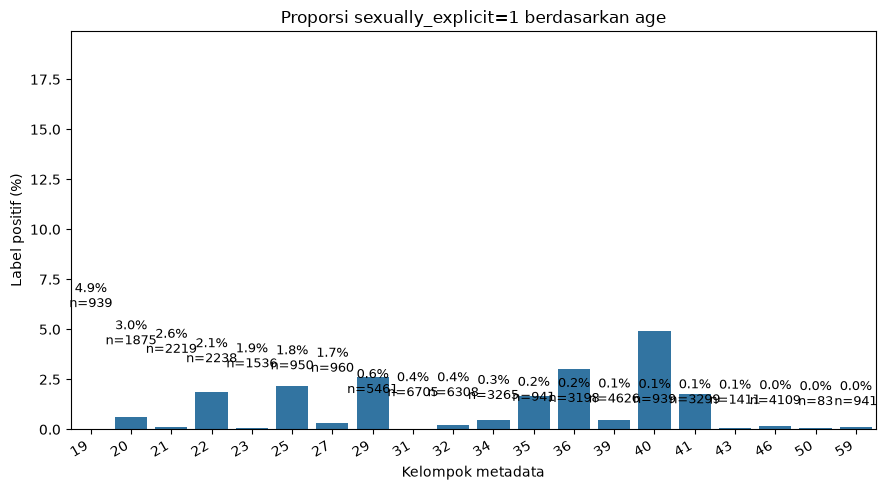

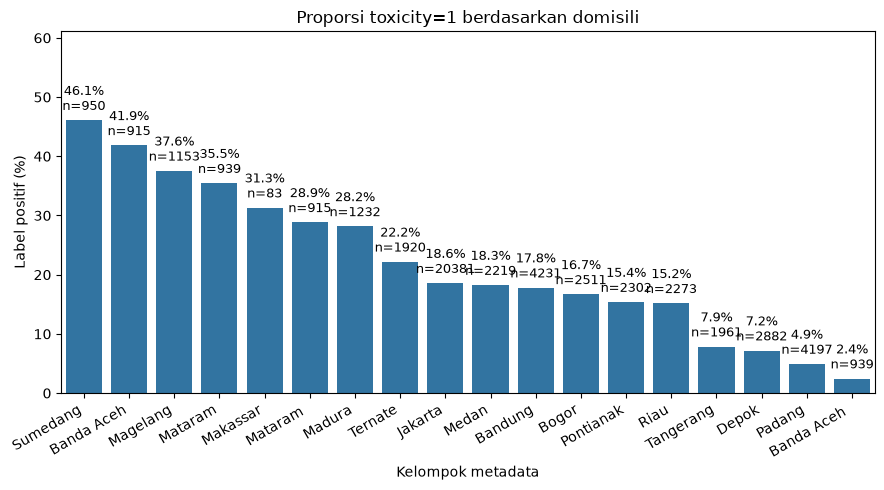

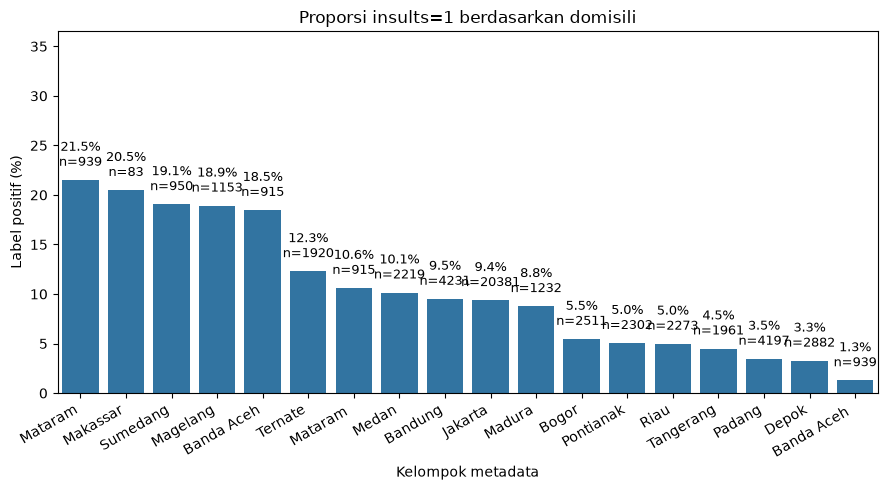

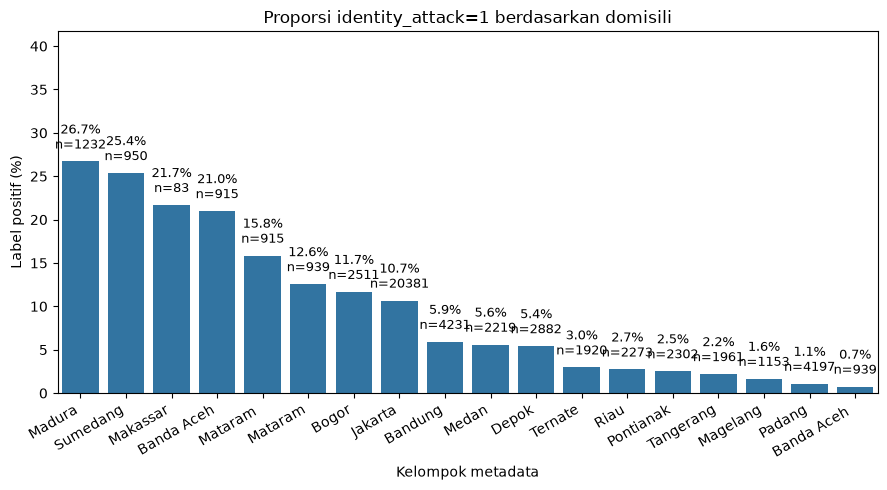

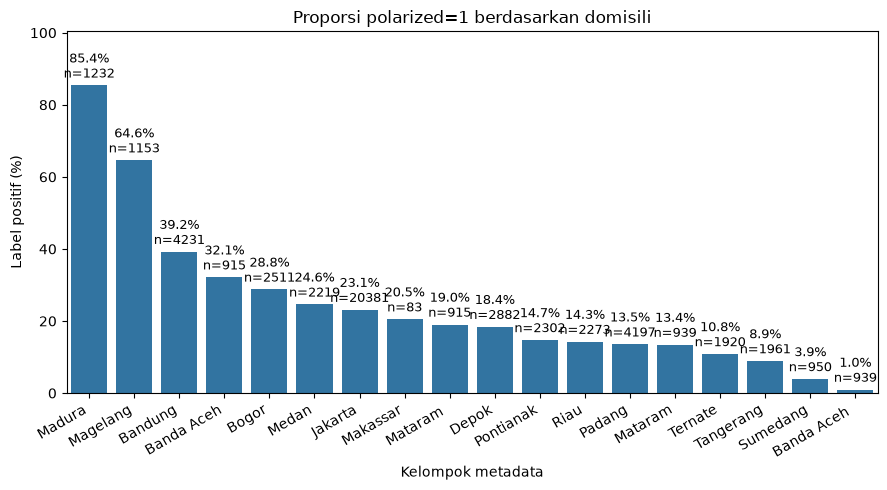

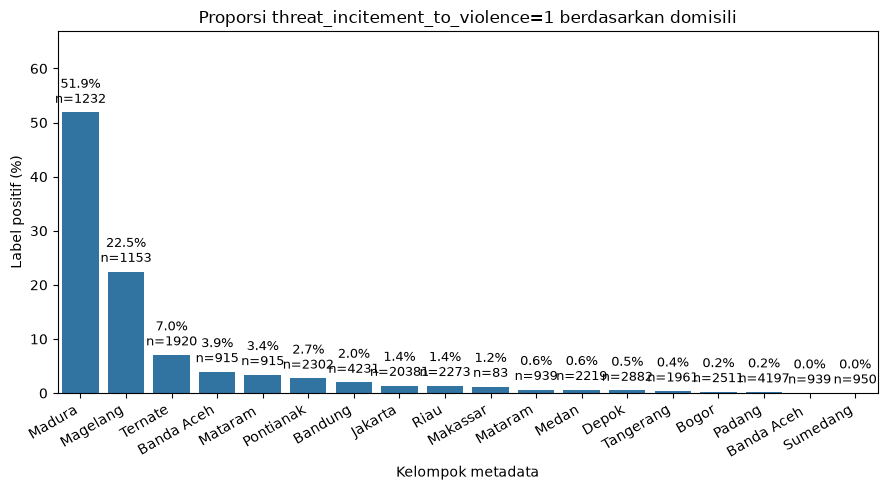

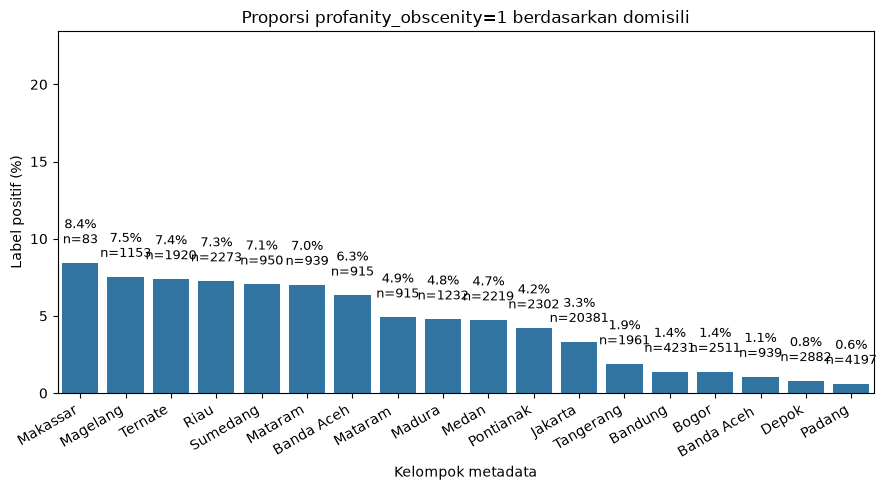

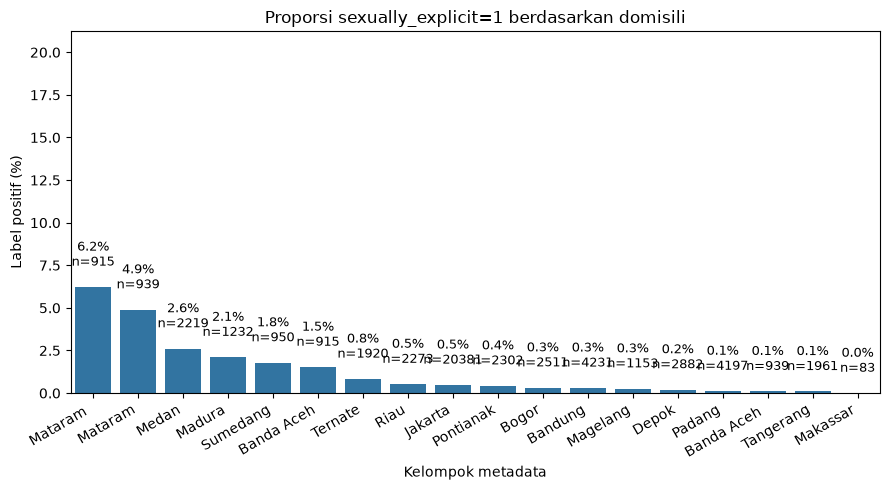

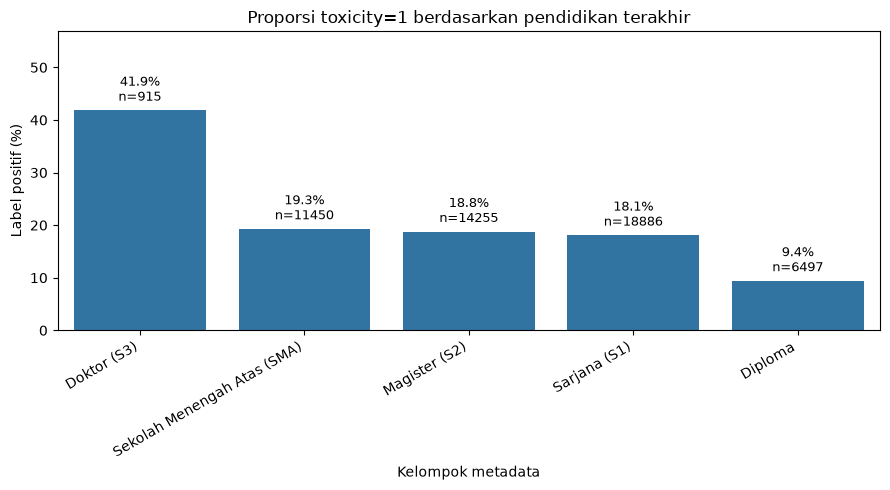

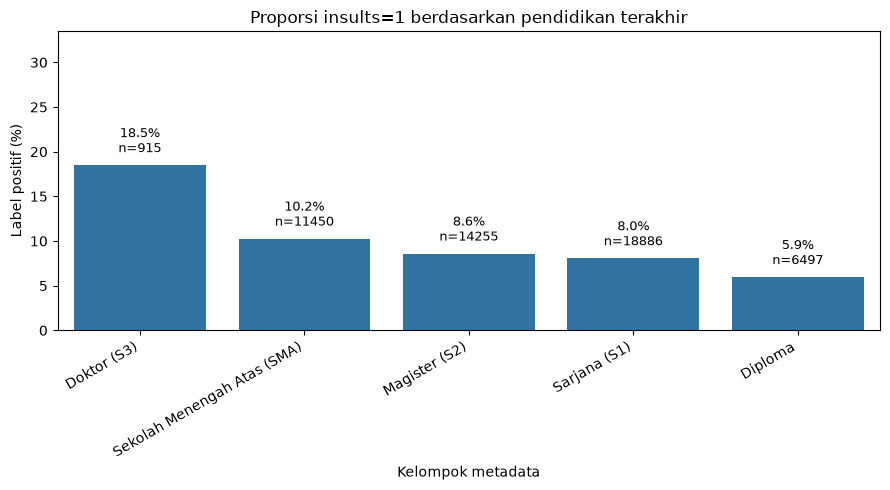

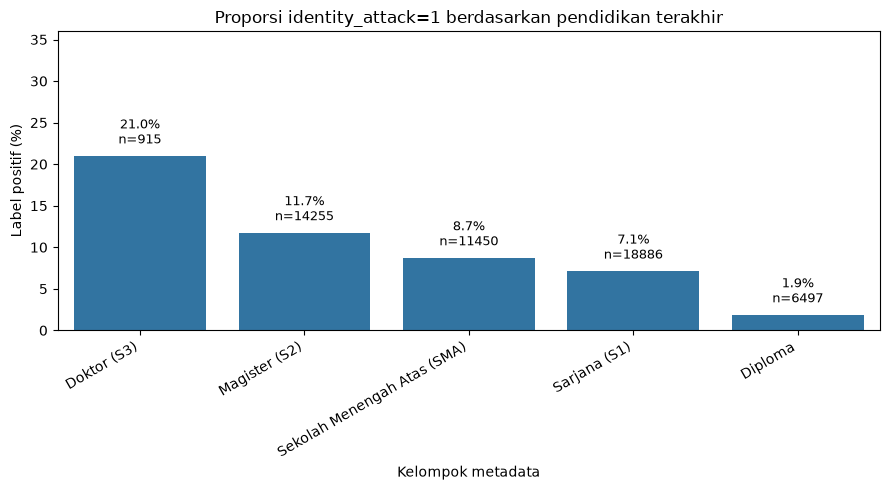

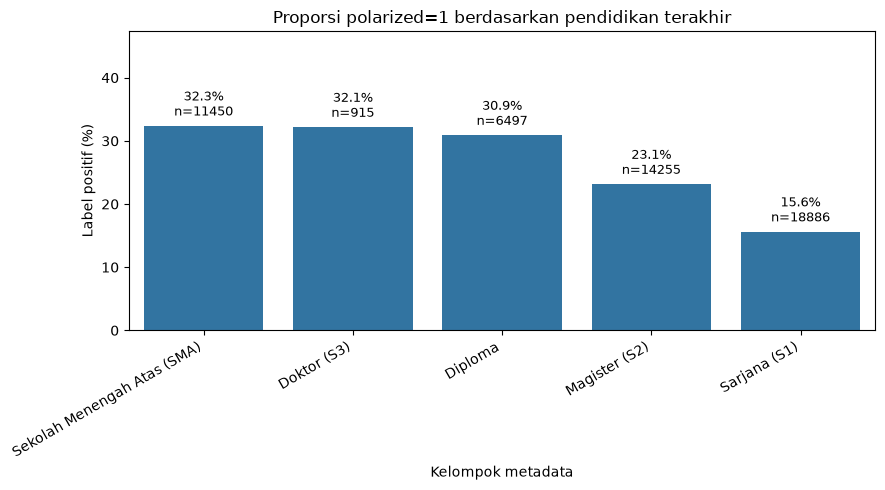

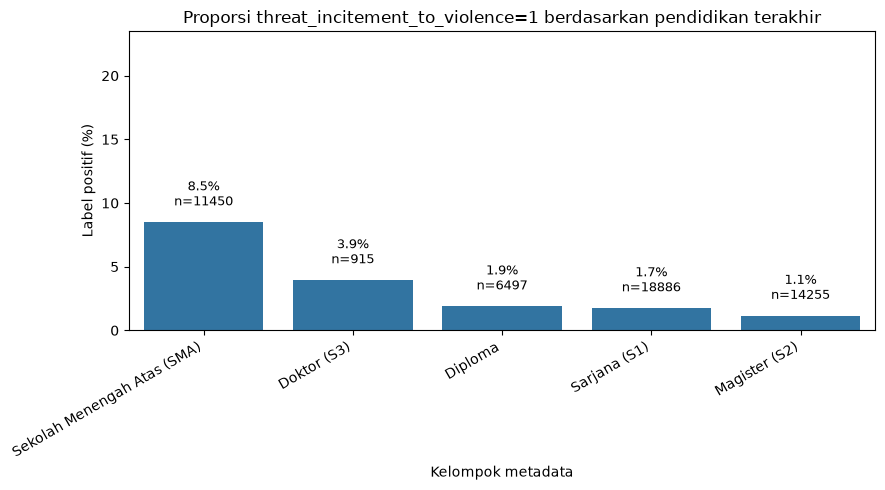

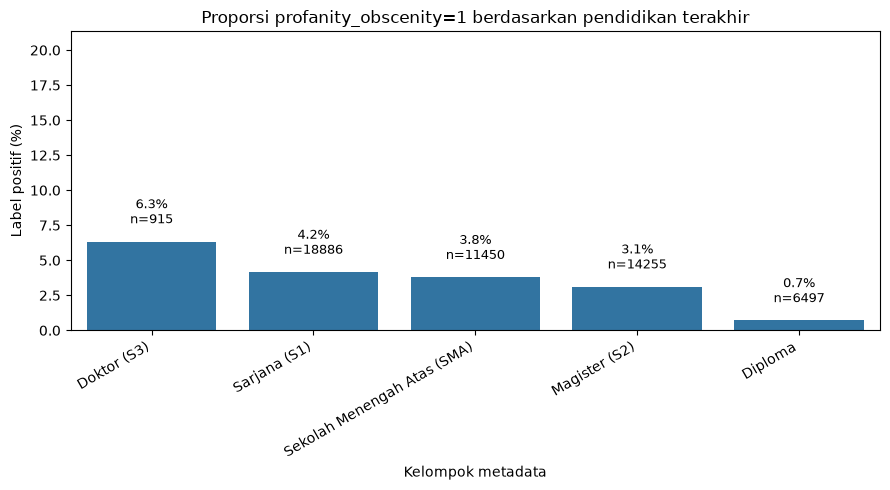

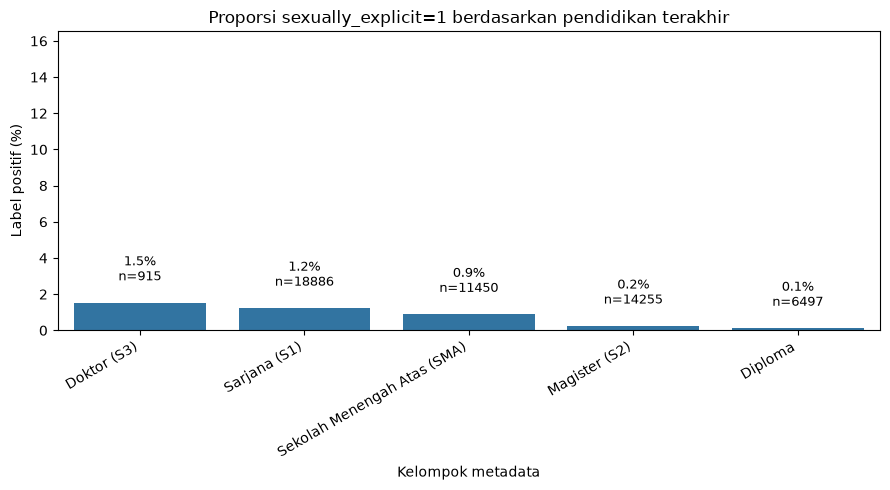

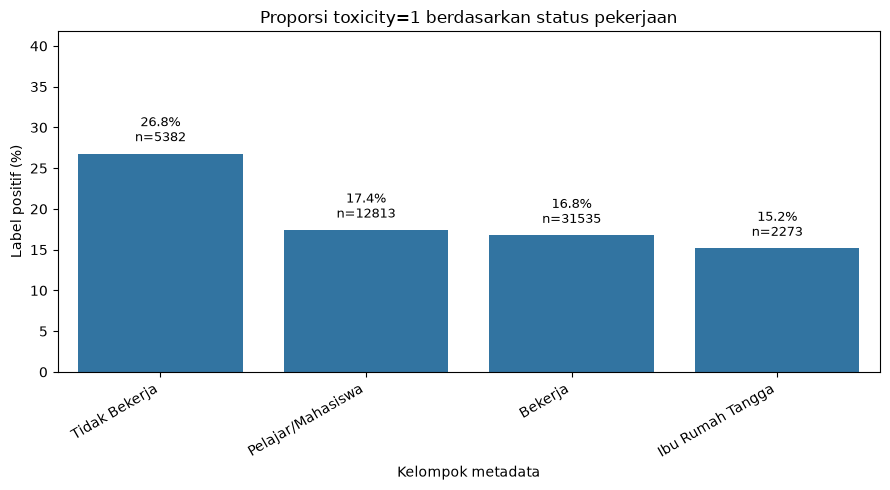

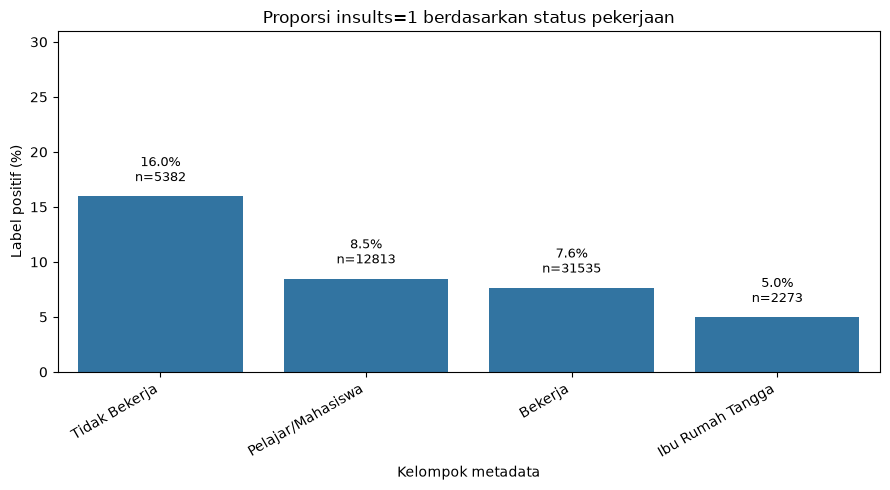

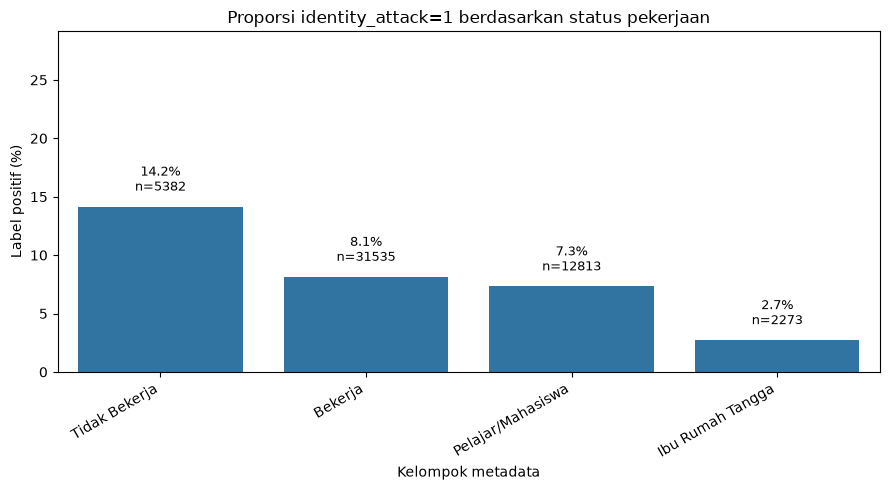

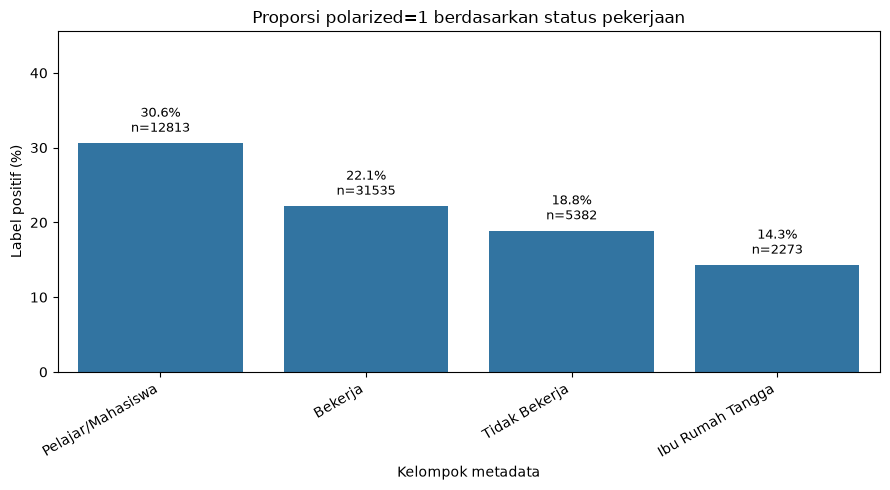

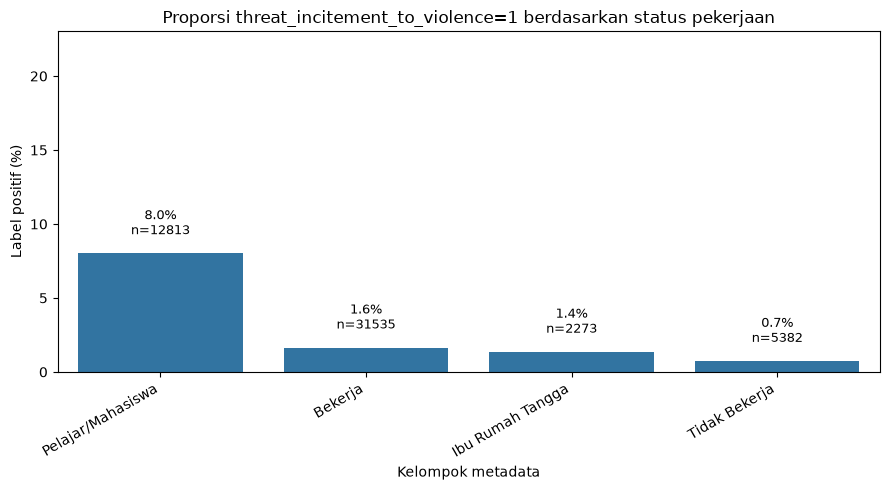

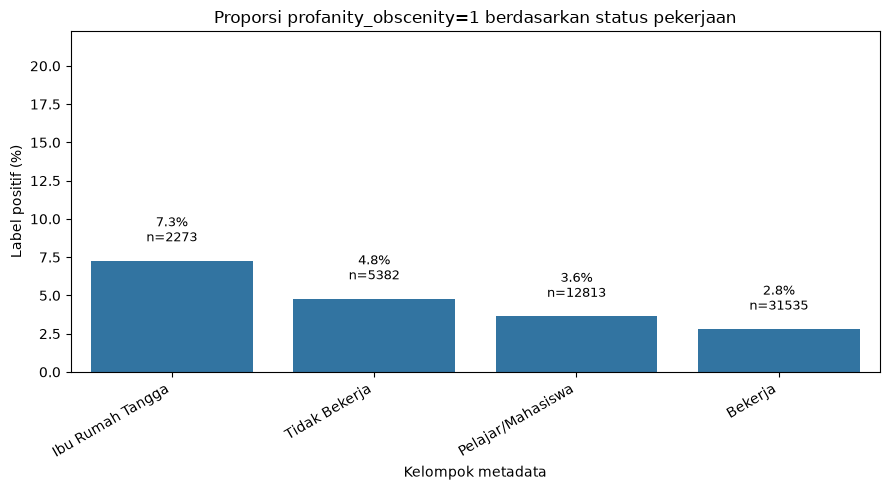

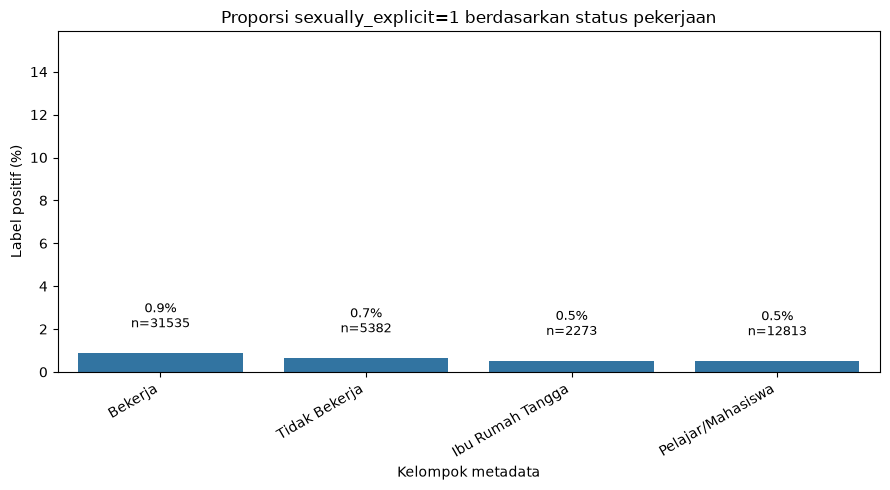

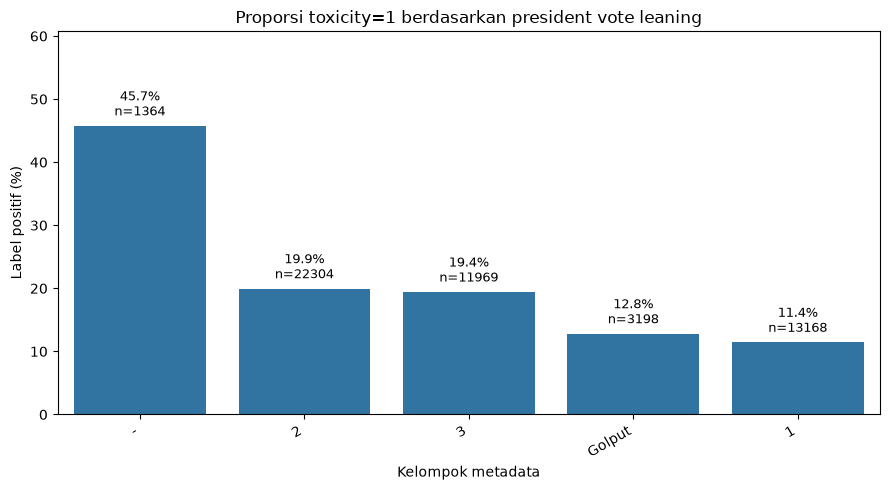

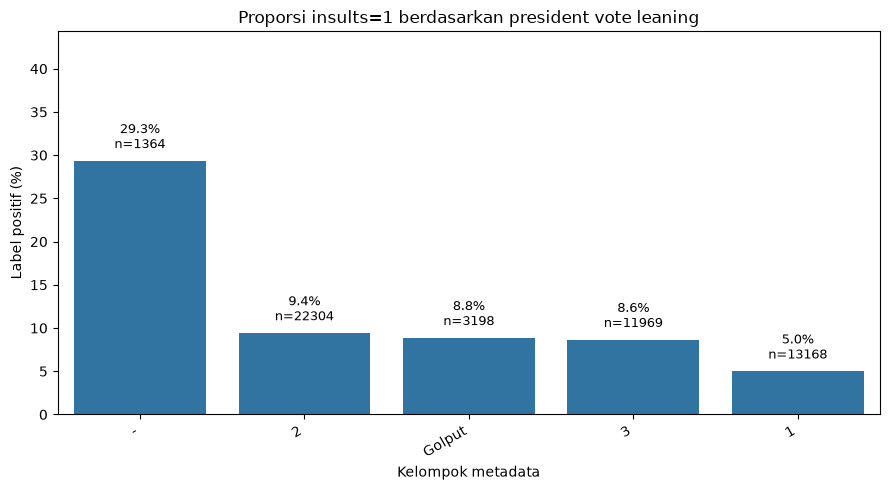

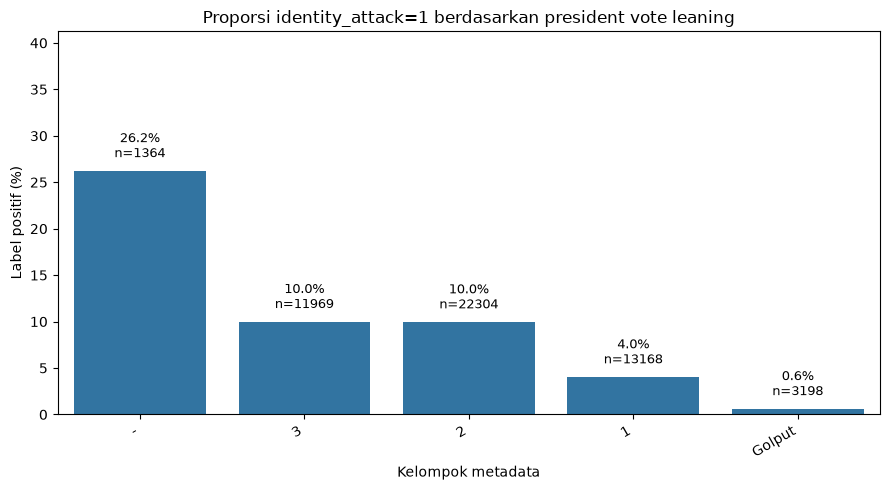

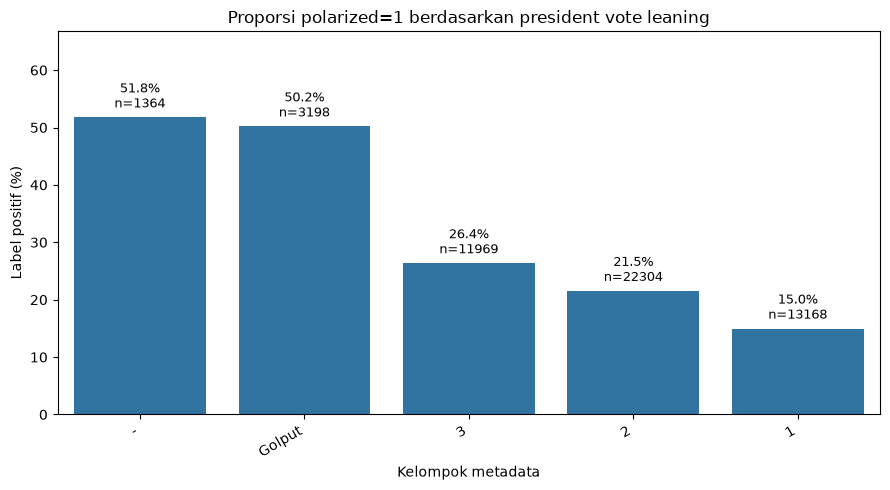

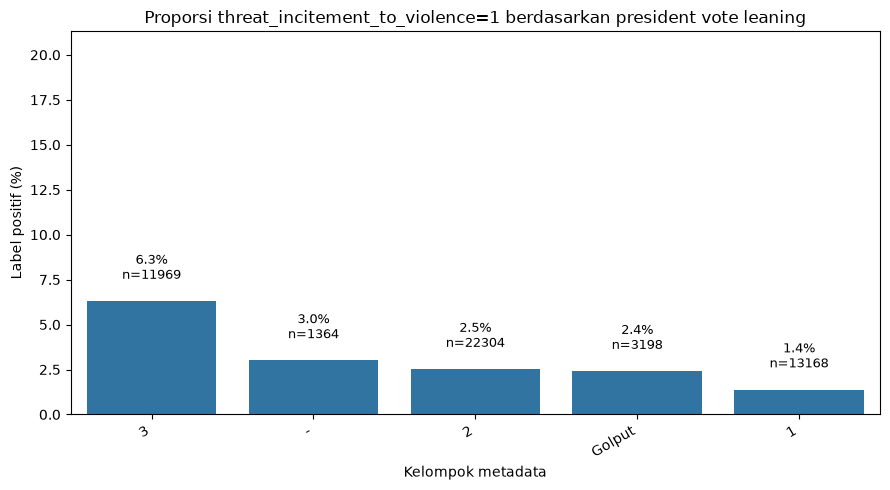

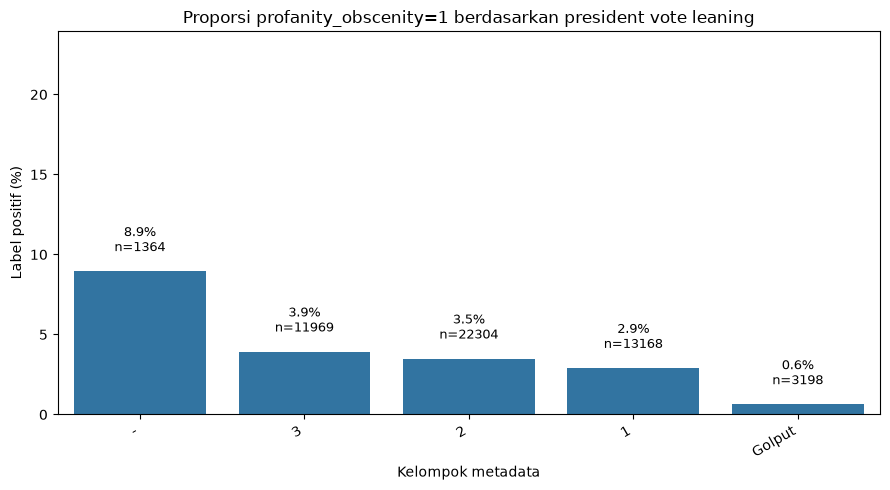

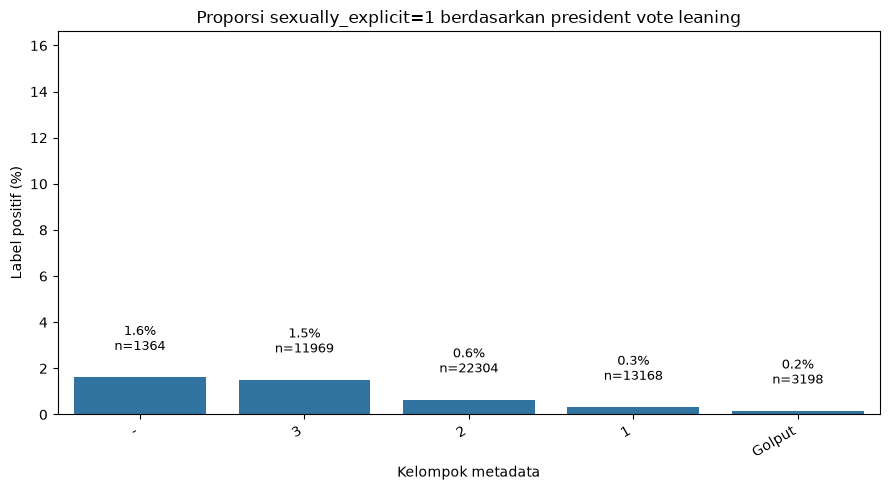

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan distribution_df sudah dibuat dari kode sebelumnya

for meta in METADATA_COLS:
    for label in LABEL_COLS:

        subset = distribution_df[
            (distribution_df["metadata"] == meta) &
            (distribution_df["label"] == label)
        ].copy()

        if subset.empty:
            continue

        subset = subset.sort_values(
            "positive_pct", ascending=False
        )

        plt.figure(figsize=(9, 5))

        ax = sns.barplot(
            data=subset,
            x="group",
            y="positive_pct"
        )

        # Tambahkan persentase dan jumlah observasi
        for i, (_, row) in enumerate(subset.iterrows()):
            ax.text(
                i,
                row["positive_pct"] + 1,
                f'{row["positive_pct"]:.1f}%\n'
                f'n={row["total"]}',
                ha="center",
                va="bottom",
                fontsize=9
            )

        plt.title(f"Proporsi {label}=1 berdasarkan {meta}")
        plt.xlabel("Kelompok metadata")
        plt.ylabel("Label positif (%)")
        plt.ylim(
            0,
            min(115, max(10, subset["positive_pct"].max() + 15))
        )
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()
